[QUICKEST scheme](https://doi.org/10.1007/3-540-45262-1_86)
[QUICK scheme (Wikipedia)](https://en.wikipedia.org/wiki/QUICK_scheme)
[Upwind scheme (Wikipedia)](https://en.wikipedia.org/wiki/Upwind_scheme)

Other schemes:
- ULTIMATE-QUICKEST,
- TVD,
- MUSCL,
- WENO.


In [1]:
from types import SimpleNamespace
import pint
import numpy as np
import matplotlib.pyplot as plt
import numba

si = pint.UnitRegistry()
si.setup_matplotlib()

%config InlineBackend.figure_formats = ['svg']



In [2]:
from itertools import product
from pint.errors import UndefinedUnitError, OffsetUnitCalculusError


class FakeUnitRegistry:  # pylint: disable=too-few-public-methods
    def __init__(self, si):
        self.dimensionless = 1.0
        for prefix, unit, suffix in product(
            si._prefixes,
            tuple(v for vs in si._units_casei.values() for v in vs),
            si._suffixes,
        ):
            name = prefix + unit + suffix
            try:
                self.__setattr__(
                    name, (1.0 * si.__getattr__(name)).to_base_units().magnitude
                )
            except (UndefinedUnitError, OffsetUnitCalculusError):
                pass

In [3]:
# si = FakeUnitRegistry(pint.UnitRegistry())

In [4]:
def courant_numbers(dt, dx, diffusion_ceoff, advection_ceoff):
    courant_advection = advection_ceoff * dt / dx
    courant_diffusion = diffusion_ceoff * dt / dx**2
    assert abs(courant_advection) <= 1
    assert courant_diffusion <= 0.5
    # TODO add assert

    return courant_advection, courant_diffusion

# TODO compile with numba
def quickest_scheme(c_new, c_old, Cd, Ca):
    halo = 2
    c_new[halo:-halo] = (
            c_old[halo-2:-halo-2] * Ca * (Cd + (Ca**2 - 1) / 6)
            + c_old[halo-1:-halo-1] * (Cd * (1 - 3*Ca) - Ca / 2 * (Ca**2 - Ca - 2))
            + c_old[halo:-halo] * (1 - Cd * (2 - 3*Ca) + Ca / 2 * (Ca**2 - 2*Ca - 1))
            + c_old[halo+1:-halo+1] * (Cd * (1 - Ca) - Ca / 6 * (Ca**2 - 3*Ca + 2))
    )
    return c_new

def upwind_scheme(c_new, c_old, Cd, Ca):
    c_new[1:-1] = (
        c_old[1:-1]
        - Ca * (c_old[1:-1] - c_old[:-2])
        + Cd * (
            c_old[2:] - 2*c_old[1:-1] + c_old[:-2]
        )
    )

    return c_new

In [5]:
def superbee_limiter(r):
    return np.maximum(
        0.0,
        np.maximum(
            np.minimum(2.0 * r, 1.0),
            np.minimum(r, 2.0)
        )
    )


def muscl_superbee_scheme(c_new, c_old, Cd, Ca):
    n = len(c_old)

    delta_left = c_old[1:-1] - c_old[:-2]
    delta_right = c_old[2:] - c_old[1:-1]

    r = np.zeros_like(delta_left) * si.dimensionless

    mask = np.abs(delta_right).m > 1e-14
    r[mask] = delta_left[mask] / delta_right[mask]

    flux = np.zeros(n + 1) * si.g/si.m**3
    flux[2:n] = Ca * (c_old[1:-1] + 0.5 * superbee_limiter(r) * delta_right)

    diff_flux = np.zeros(n + 1) * si.g/si.m**3
    diff_flux[1:n] = -Cd * (c_old[1:] - c_old[:-1])

    total_flux = flux + diff_flux

    c_new[1:-1] = c_old[1:-1] - (total_flux[2:n] - total_flux[1:n-1])

    return c_new

TODO:
- add just-in-time compilation
- check edge cases

In [6]:
def simulation(n_timesteps, n_x, data, scheme=quickest_scheme, save_span=1):
    assert data.river_velocity >= 0

    n_savesteps = n_timesteps // save_span
    dx = (data.L_in + data.L_out) / n_x
    dt = data.time / n_timesteps


    result = SimpleNamespace(
        concentration = np.empty((n_x, n_savesteps+1)) * si.g/si.m**3,
        x = np.arange(0, n_x) * dx,
        times = np.arange(0, n_savesteps+1) * dt * save_span,
    )

    halo = 2
    c_new = np.zeros((n_x + 2*halo, )) * si.g/si.m**3
    c_old = np.zeros((n_x + 2*halo, )) * si.g/si.m**3

    # TODO initial condition
    c_old[5:24] = data.marker_mass / data.cross_section_area / dx / 4
    result.concentration[:, 0] = c_old[halo:-halo]
    idx = 1


    courant_advection, courant_diffusion = courant_numbers(
        dt, dx,
        diffusion_ceoff=data.diffusion_coeff,
        advection_ceoff=data.river_velocity
    )

    for j in range(n_timesteps):
        c_new = scheme(c_new, c_old, courant_diffusion, courant_advection)
        c_new[:halo+1] = c_new[-halo-1:] = 0 * si.g/si.m**3
        c_old[:] = c_new[:]

        if j % save_span == 0:
            result.concentration[:, idx] = c_new[halo:-halo]
            idx += 1

    return result

In [7]:
constants = lambda: SimpleNamespace(
    L_in = 10 * si.m,
    L_out = 2900 * si.m,
    cross_section_area = 10 * si.m**2,
    river_velocity = 0.1 * si.m / si.s,
    diffusion_coeff = 0.0 * si.m**2 / si.s,
    marker_mass = 10 * si.kg,
    time = 500 * si.min,
)

In [8]:
c = constants()
result_quickest = simulation(n_timesteps=(n_t:=300), n_x=(n_x:=100), data=c, scheme=quickest_scheme,save_span=10)
result_upwind = simulation(n_timesteps=(n_t:=300), n_x=(n_x:=100), data=c, scheme=upwind_scheme, save_span=10)
result_superbee = simulation(n_timesteps=(n_t:=300), n_x=(n_x:=100), data=c, scheme=muscl_superbee_scheme, save_span=10)

In [9]:
def plot_profiles(result, title=""):
    plt.figure(figsize=(9, 5))

    n = len(result.times)
    for i in np.linspace(0, n-1, 6, dtype=int):
        plt.plot(result.x, result.concentration[:, i],
                 linewidth=2, label=f"t={result.times[i]:.2f}")

    plt.title(title)
    plt.grid(alpha=0.3, linestyle="--")
    plt.legend()
    plt.tight_layout()
    plt.show()

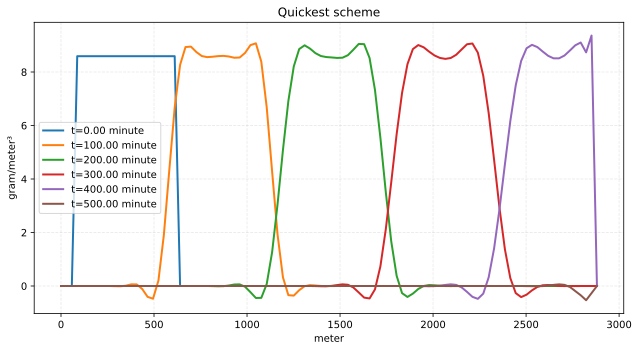

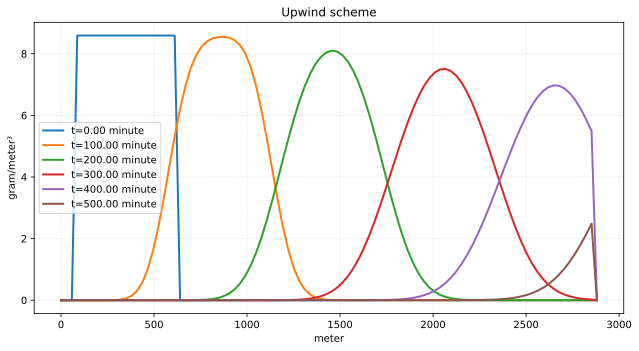

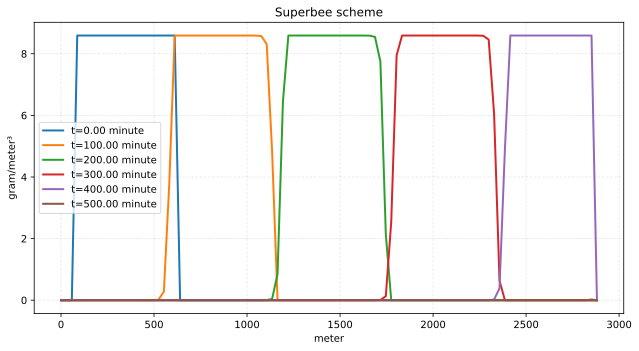

In [10]:
plot_profiles(result_quickest, title="Quickest scheme")
plot_profiles(result_upwind, title="Upwind scheme")
plot_profiles(result_superbee, title="Superbee scheme")